In [1]:
# Basic libraries used for data analysis
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make tables easier to read in the notebook
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')

# Project paths. The notebook is inside /notebooks, so '..' means the project root.
PROJECT_ROOT = Path('..').resolve()
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
FIGURES_DIR = PROJECT_ROOT / 'report' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RAW_FILES = {
    'dim_client': RAW_DIR / 'dim_client.xlsx',
    'dim_product': RAW_DIR / 'dim_product.xlsx',
    'fact_sales': RAW_DIR / 'fact_sales.xlsx',
}

RAW_FILES

{'dim_client': WindowsPath('C:/Users/bochr/OneDrive/Documents/projet Medis/data/raw/dim_client.xlsx'),
 'dim_product': WindowsPath('C:/Users/bochr/OneDrive/Documents/projet Medis/data/raw/dim_product.xlsx'),
 'fact_sales': WindowsPath('C:/Users/bochr/OneDrive/Documents/projet Medis/data/raw/fact_sales.xlsx')}

In [2]:
def load_excel(path):
    #Load an Excel file and return a DataFrame. If the file has many sheets, this loads the first sheet. Most simple project files use one sheet per Excel file.
    
    try:
        excel_file = pd.ExcelFile(path)
        print(f'{path.name}: sheets = {excel_file.sheet_names}')
        return pd.read_excel(path, sheet_name=excel_file.sheet_names[0])
    except PermissionError:
        raise PermissionError(
            f'Cannot read {path}. Close the file in Excel/OneDrive sync and run again.'
        )


# Load the 3 raw tables into a dictionary.
tables = {name: load_excel(path) for name, path in RAW_FILES.items()}

# Show table sizes.
for name, df in tables.items():
    print(f'{name}: {df.shape[0]:,} rows x {df.shape[1]:,} columns')

dim_client.xlsx: sheets = ['Feuil1']
dim_product.xlsx: sheets = ['Feuil1']
fact_sales.xlsx: sheets = ['Feuil1']
dim_client: 1,173 rows x 15 columns
dim_product: 2,882 rows x 17 columns
fact_sales: 295,338 rows x 8 columns


In [3]:
# Display the first rows and column names for each table.
# This is where we start understanding what the data contains.
for name, df in tables.items():
    print('\n' + '=' * 80)
    print(name.upper())
    print('=' * 80)
    print('Columns:')
    print(list(df.columns))
    display(df.head())


DIM_CLIENT
Columns:
['CodeClient', 'Client', 'Type', 'Marche', 'Pays', 'Region', 'Continent', 'Domaine', 'Critere', 'Section', 'TXCOMMSION', 'ICO', 'Country', 'Condition_paiement', 'Mode_facturation']


,CodeClient,Client,Type,Marche,Pays,Region,Continent,Domaine,Critere,Section,TXCOMMSION,ICO,Country,Condition_paiement,Mode_facturation
0,AFNSS000,AFRIQUE NOIRE SUBSAHARIENNE,Autre,Autre,Autre,Region,Autre,Autre,Autre,Autres,0,Client,NaN,VIR90J,1 fac/cli livré
1,AL-SHEFA,AL-SHEFA INTERNATIONAL DRUG STORE,CLIENT GROUPE,EXPORT,JORDANIE,MOYEN ORIENT,ASIE,OFFICINE,MOYEN ORIENT,JOR01,0,Client,JORDAN,TRAITE90J,1 fac/cli livré
2,ALFAWASSER,ALFA WASSERMAN,CLIENT GROUPE,LOCAL,TUNISIE,MAGHREB,AFRIQUE,OFFICINE,OFFICINE,TN0001,0,Client,TUNISIA,CAD,1 fac/cli livré
3,ALG000,MARCHE ALGERIE,CLIENT GROUPE,EXPORT,ALGERIE,MAGHREB,AFRIQUE,OFFICINE,ALGERIE,ALG001,0,Client,ALGERIA,LC-IRR-CONF-60J,1 fac/cli livré
4,ALG000HO,MARCHE HOSPITALIER - ALGERIE,CLIENT GROUPE,EXPORT,ALGERIE,MAGHREB,AFRIQUE,HOPITAUX,ALGERIE,ALG001,0,Client,ALGERIA,LC-IRR-CONF-60J,1 fac/cli livré



DIM_PRODUCT
Columns:
['Reference Produit', 'Desgination Produit', 'Famille', 'Dosage', 'Modele', 'Forme', 'Activite', 'Nature', 'DCI', 'Societe', 'MC_Indus', 'Forme_galenique', 'INCOTERM', 'Forme_Pharmaceutique', 'Activite_ENG', 'Ancien_Code', 'Coef']


,Reference Produit,Desgination Produit,Famille,Dosage,Modele,Forme,Activite,Nature,DCI,Societe,MC_Indus,Forme_galenique,INCOTERM,Forme_Pharmaceutique,Activite_ENG,Ancien_Code,Coef
0,ABI250T120,ABIRATERONE NEAPOLIS 250 MG,ABIRATERONE,250MG,,B120,"ONCO, IMMUNO",4081100000,ABIRATERONE ABIRATERONE,NEAPOLIS,Autres,COMPRIMES,PRODUCT,COMPRIMES,1-IMMUNO. & ONCOLOGY,ABI250T120,120.0
1,ABI250T120AP,ABIRATERONE 250 MG ACCES PROG,ABIRATERONE,250MG,,B120,"ONCO, IMMUNO",4081100000,ABIRATERONE ABIRATERONE,NEAPOLIS,Autres,COMPRIMES,PRODUCT,COMPRIMES,1-IMMUNO. & ONCOLOGY,ABI250T120,120.0
2,ABI250T120LBN,ABIRATERONE NEAPOLIS 250MG LBN,ABIRATERONE,250MG,,B120,"ONCO, IMMUNO",4081100000,ABIRATERONE ABIRATERONE,NEAPOLIS,Autres,COMPRIMES,PRODUCT,COMPRIMES,1-IMMUNO. & ONCOLOGY,ABI250T120LBN,120.0
3,ACA050T090D01,ACARBOSE50MG B90 DEV,AUTRES,AUTRES,AUTRES,AUTRES,AUTRES,6011002111,AUTRES ACA050T090D01,NEAPOLIS,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ADE015T030,"ADEX LP 1,5 MG CP B30",ADEX,"1,5MG",OFFICINES,B30,"CARDIO, METAB. & RESPIRATOIRE",,ADEX ADEX,MEDIS,Dry forms,COMPRIMES,PRODUCT,COMPRIMES,"2-CARDIO., METAB. & RESPIRATORY",ADE015T030,30.0



FACT_SALES
Columns:
['Prix_Vente', 'Numéro_Facture', 'Reference_Produit', 'Code_Client', 'Date_Facture', 'Montant_Total_Vente', 'Quantité', 'Societe']


,Prix_Vente,Numéro_Facture,Reference_Produit,Code_Client,Date_Facture,Montant_Total_Vente,Quantité,Societe
0,14.373,N2500075,ARA016T030,TUN00094,2025-02-06,140.8554,10,NEAPOLIS
1,8.044,M2500453,PF005900006,TUN00125,2025-02-27,472.9872,60,MEDIS
2,8.310,M2502537,PF005300001,TUN00100,2025-12-04,97.7256,12,MEDIS
3,0.000,M2400774,PF020100003,ANS00002,2024-04-22,0.0000,8780,MEDIS
4,18.488,M2600817,PF013500010,TUN00125,2026-04-27,362.3648,20,MEDIS


In [4]:
def quick_summary(df):
    """Create a compact summary for every column in a DataFrame."""
    summary = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'missing_count': df.isna().sum(),
        'missing_percent': (df.isna().mean() * 100).round(2),
        'unique_values': df.nunique(dropna=True),
    })
    return summary.sort_values(['missing_percent', 'unique_values'], ascending=[False, False])


for name, df in tables.items():
    print('\n' + '=' * 80)
    print(f'{name.upper()} - SUMMARY')
    print('=' * 80)
    print(f'Duplicate rows: {df.duplicated().sum():,}')
    display(quick_summary(df))


DIM_CLIENT - SUMMARY
Duplicate rows: 0


,dtype,missing_count,missing_percent,unique_values
Country,str,26,2.22,53
Critere,str,6,0.51,29
CodeClient,str,0,0.00,1173
Client,str,0,0.00,609
Pays,str,0,0.00,51
Condition_paiement,str,0,0.00,51
Section,str,0,0.00,43
Region,str,0,0.00,11
Type,str,0,0.00,10
TXCOMMSION,object,0,0.00,10



DIM_PRODUCT - SUMMARY
Duplicate rows: 0


,dtype,missing_count,missing_percent,unique_values
Ancien_Code,str,801,27.79,1355
Forme_galenique,str,771,26.75,17
MC_Indus,str,761,26.41,3
Forme_Pharmaceutique,str,709,24.60,20
Activite_ENG,str,700,24.29,20
Coef,float64,698,24.22,47
INCOTERM,str,698,24.22,3
Forme,object,483,16.76,37
Dosage,object,341,11.83,116
Modele,str,100,3.47,10



FACT_SALES - SUMMARY
Duplicate rows: 2,518


,dtype,missing_count,missing_percent,unique_values
Montant_Total_Vente,float64,0,0.0,21938
Numéro_Facture,str,0,0.0,11548
Prix_Vente,float64,0,0.0,3752
Quantité,int64,0,0.0,3581
Date_Facture,datetime64[us],0,0.0,825
Reference_Produit,str,0,0.0,646
Code_Client,str,0,0.0,170
Societe,str,0,0.0,2


In [5]:
# Numeric summaries help us detect strange values such as negative quantities or very large outliers.
for name, df in tables.items():
    numeric_cols = df.select_dtypes(include='number').columns
    if len(numeric_cols) == 0:
        print(f'{name}: no numeric columns detected')
        continue
    print('\n' + '=' * 80)
    print(f'{name.upper()} - NUMERIC SUMMARY')
    print('=' * 80)
    display(df[numeric_cols].describe().T)

dim_client: no numeric columns detected

DIM_PRODUCT - NUMERIC SUMMARY


,count,mean,std,min,25%,50%,75%,max
Coef,2184.0,17.891026,29.297611,1.0,1.0,4.0,30.0,300.0



FACT_SALES - NUMERIC SUMMARY


,count,mean,std,min,25%,50%,75%,max
Prix_Vente,295338.0,22.433667,101.985044,0.000000e+00,6.48907,12.00,22.86600,11880.0
Montant_Total_Vente,295338.0,3493.690593,25218.758995,-1.339037e+06,243.23600,599.76,1702.75392,1631450.0
Quantité,295338.0,462.723195,12488.741386,-2.476910e+06,20.00000,48.00,144.00000,2476910.0


In [6]:
# Try to detect date columns and show their date ranges.
# We use errors='coerce': invalid dates become NaT instead of crashing the notebook.
for name, df in tables.items():
    print('\n' + '=' * 80)
    print(f'{name.upper()} - POSSIBLE DATE COLUMNS')
    print('=' * 80)
    found_date = False
    for col in df.columns:
        col_lower = str(col).lower()
        if 'date' in col_lower or 'jour' in col_lower or 'time' in col_lower:
            dates = pd.to_datetime(df[col], errors='coerce')
            if dates.notna().sum() > 0:
                found_date = True
                print(f'{col}: {dates.min().date()} -> {dates.max().date()} | valid dates: {dates.notna().sum():,}')
    if not found_date:
        print('No obvious date column found by name. We will handle this again after cleaning.')


DIM_CLIENT - POSSIBLE DATE COLUMNS
No obvious date column found by name. We will handle this again after cleaning.

DIM_PRODUCT - POSSIBLE DATE COLUMNS
No obvious date column found by name. We will handle this again after cleaning.

FACT_SALES - POSSIBLE DATE COLUMNS
Date_Facture: 2023-01-02 -> 2026-04-30 | valid dates: 295,338


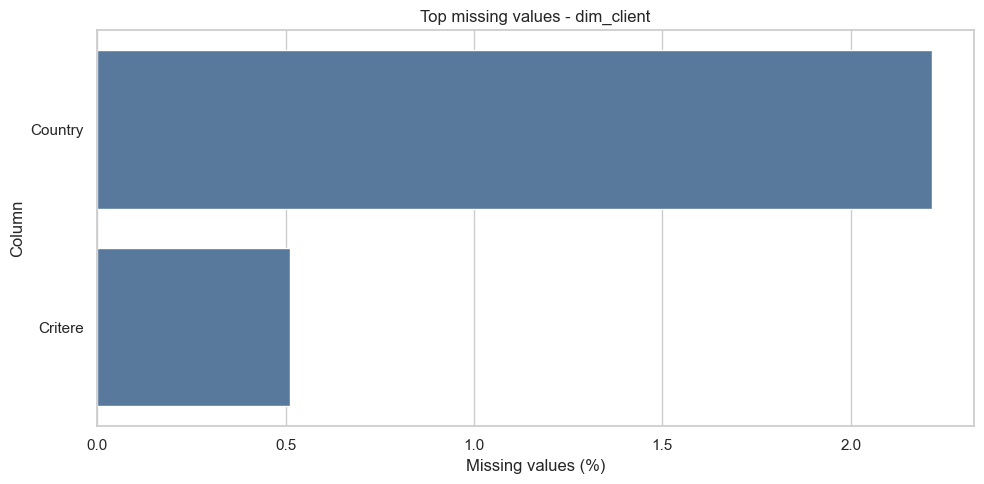

Saved: C:\Users\bochr\OneDrive\Documents\projet Medis\report\figures\01_missing_dim_client.png


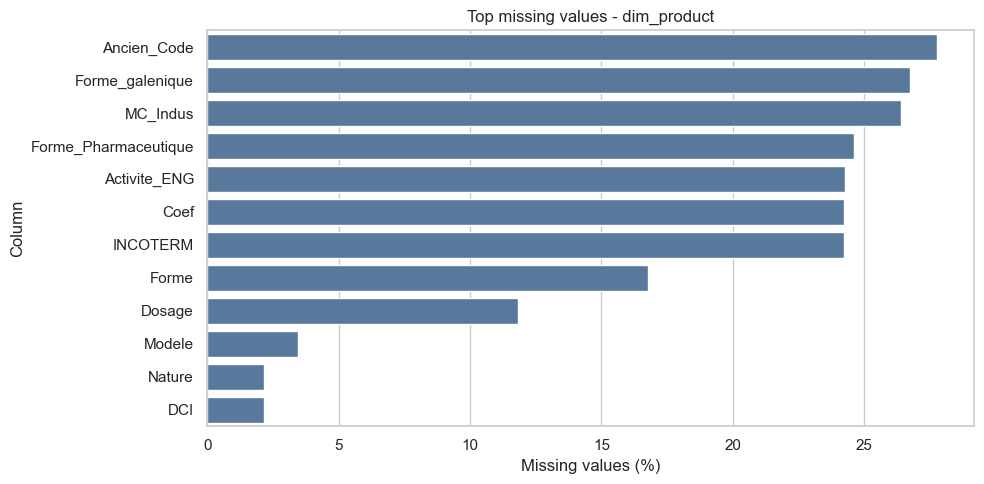

Saved: C:\Users\bochr\OneDrive\Documents\projet Medis\report\figures\01_missing_dim_product.png
fact_sales: no missing values to plot


In [7]:
# Save simple missing-value plots for the report.
for name, df in tables.items():
    missing = (df.isna().mean() * 100).sort_values(ascending=False).head(20)
    missing = missing[missing > 0]
    if missing.empty:
        print(f'{name}: no missing values to plot')
        continue

    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing.values, y=missing.index, color='#4C78A8')
    plt.title(f'Top missing values - {name}')
    plt.xlabel('Missing values (%)')
    plt.ylabel('Column')
    plt.tight_layout()
    output_path = FIGURES_DIR / f'01_missing_{name}.png'
    plt.savefig(output_path, dpi=150)
    plt.show()
    print(f'Saved: {output_path}')

## What to write in the report after this notebook

Use the outputs above to describe:
- Number of rows and columns in each table.
- The role of each table: `dim_client`, `dim_product`, and `fact_sales`.
- Important missing values.
- Duplicate rows, if any.
- Date range of sales, if a sales date column exists.
- Any strange values that need cleaning.